In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pulp

from pathlib import Path

In [23]:
# Making simulated results reproducible
np.random.seed(42)

In [22]:
# Creating a folder for project outputs
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# Defining the Planning Calender

In [2]:
# Planning period: October to December 2026
planning_start = "2026-10-19"
planning_end = "2026-12-28"

# Each date represents the Monday starting a planning week
week_starts = pd.date_range(
    start="2026-10-19",
    end="2026-12-28",
    freq="W-MON"
)

print("Number of planning weeks:", len(week_starts))
print("First planning week:", week_starts[0].date())
print("Last planning week:", week_starts[-1].date())

Number of planning weeks: 11
First planning week: 2026-10-19
Last planning week: 2026-12-28


In [ ]:
# Defining the biscuit products

In [3]:
skus = [
    "Yale Cabin 25g",
    "Yale Glucose 35g",
    "Yale Speedy Chocolate 40g",
    "Sumal Shortcake"
]

# Illustrative weekly baseline demand in packs
base_demand = {
    "Yale Cabin 25g": 800_000,
    "Yale Glucose 35g": 650_000,
    "Yale Speedy Chocolate 40g": 500_000,
    "Sumal Shortcake": 400_000
}

products_df = pd.DataFrame({
    "sku": skus,
    "base_weekly_demand": [
        base_demand[sku] for sku in skus
    ]
})

display(products_df)

,sku,base_weekly_demand
0,Yale Cabin 25g,800000
1,Yale Glucose 35g,650000
2,Yale Speedy Chocolate 40g,500000
3,Sumal Shortcake,400000


In [ ]:
 # Generating weekly festive demand forecast 

In [4]:
demand_records = []

for week_number, week_start in enumerate(week_starts):

    # Demand rises progressively through the festive quarter
    seasonal_factor = 1 + (0.08 * week_number)

    for sku in skus:

        baseline = base_demand[sku]

        # Add random demand variation of approximately 6%
        simulated_demand = np.random.normal(
            loc=baseline * seasonal_factor,
            scale=baseline * seasonal_factor * 0.06
        )

        demand_records.append({
            "week_start": week_start,
            "sku": sku,
            "forecast_units": max(
                0, round(simulated_demand)
            ),
            "seasonal_factor": round(seasonal_factor, 2)
        })

df_demand = pd.DataFrame(demand_records)

display(df_demand.head(10))

,week_start,sku,forecast_units,seasonal_factor
0,2026-10-19,Yale Cabin 25g,799662,1.00
1,2026-10-19,Yale Glucose 35g,642371,1.00
2,2026-10-19,Yale Speedy Chocolate 40g,515609,1.00
3,2026-10-19,Sumal Shortcake,392133,1.00
4,2026-10-26,Yale Cabin 25g,898407,1.08
5,2026-10-26,Yale Glucose 35g,650130,1.08
6,2026-10-26,Yale Speedy Chocolate 40g,512051,1.08
7,2026-10-26,Sumal Shortcake,447300,1.08
8,2026-11-02,Yale Cabin 25g,910034,1.16
9,2026-11-02,Yale Glucose 35g,734509,1.16


In [ ]:
# Inspecting Demand Forecast

In [5]:
weekly_demand = (
    df_demand
    .groupby("week_start", as_index=False)["forecast_units"]
    .sum()
)

sku_demand = (
    df_demand
    .groupby("sku", as_index=False)["forecast_units"]
    .sum()
    .sort_values("forecast_units", ascending=False)
)

print("Total forecast demand for Q4:")
print(f"{df_demand['forecast_units'].sum():,.0f} packs")

print("\nForecast demand by product:")
display(sku_demand)

print("\nWeekly demand:")
display(weekly_demand)

Total forecast demand for Q4:
36,369,891 packs

Forecast demand by product:


,sku,forecast_units
1,Yale Cabin 25g,12536609
2,Yale Glucose 35g,10056187
3,Yale Speedy Chocolate 40g,7615545
0,Sumal Shortcake,6161550



Weekly demand:


,week_start,forecast_units
0,2026-10-19,2349775
1,2026-10-26,2507888
2,2026-11-02,2571858
3,2026-11-09,2994806
4,2026-11-16,3178866
5,2026-11-23,3291382
6,2026-11-30,3636937
7,2026-12-07,3862211
8,2026-12-14,3706670
9,2026-12-21,4029005


In [ ]:
# Visualizing the festive demand trend

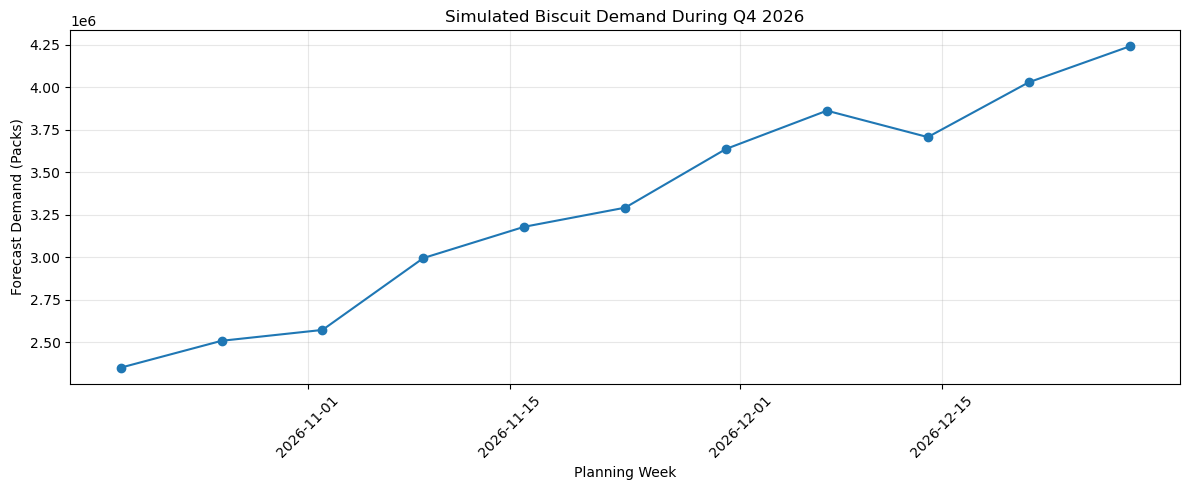

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    weekly_demand["week_start"],
    weekly_demand["forecast_units"],
    marker="o"
)

plt.title("Simulated Biscuit Demand During Q4 2026")
plt.xlabel("Planning Week")
plt.ylabel("Forecast Demand (Packs)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Creating the Bill of Materials

In [11]:
bom_records = [
    ("Yale Cabin 25g", "Wheat flour", 0.015),
    ("Yale Cabin 25g", "Sugar", 0.004),
    ("Yale Cabin 25g", "Packaging film", 1.0),

    ("Yale Glucose 35g", "Wheat flour", 0.020),
    ("Yale Glucose 35g", "Sugar", 0.006),
    ("Yale Glucose 35g", "Packaging film", 1.0),

    ("Yale Speedy Chocolate 40g", "Wheat flour", 0.018),
    ("Yale Speedy Chocolate 40g", "Sugar", 0.006),
    ("Yale Speedy Chocolate 40g", "Cocoa powder", 0.004),
    ("Yale Speedy Chocolate 40g", "Packaging film", 1.0),

    ("Sumal Shortcake", "Wheat flour", 0.020),
    ("Sumal Shortcake", "Sugar", 0.005),
    ("Sumal Shortcake", "Vegetable fat", 0.006),
    ("Sumal Shortcake", "Packaging film", 1.0)
]

df_bom = pd.DataFrame(
    bom_records,
    columns=["sku", "material", "qty_per_unit"]
)

display(df_bom)

,sku,material,qty_per_unit
0,Yale Cabin 25g,Wheat flour,0.015
1,Yale Cabin 25g,Sugar,0.004
2,Yale Cabin 25g,Packaging film,1.000
3,Yale Glucose 35g,Wheat flour,0.020
4,Yale Glucose 35g,Sugar,0.006
5,Yale Glucose 35g,Packaging film,1.000
6,Yale Speedy Chocolate 40g,Wheat flour,0.018
7,Yale Speedy Chocolate 40g,Sugar,0.006
8,Yale Speedy Chocolate 40g,Cocoa powder,0.004
9,Yale Speedy Chocolate 40g,Packaging film,1.000


In [ ]:
# Defining initital warehouse inventory 

In [13]:
initial_inventory = {
    "Wheat flour": 2_500,
    "Sugar": 700,
    "Cocoa powder": 100,
    "Vegetable fat": 300,
    "Packaging film": 150_000
}

df_inventory = pd.DataFrame(
    list(initial_inventory.items()),
    columns=["material", "opening_stock"]
)

display(df_inventory)

,material,opening_stock
0,Wheat flour,2500
1,Sugar,700
2,Cocoa powder,100
3,Vegetable fat,300
4,Packaging film,150000


In [ ]:
# Module 2: Materials Planning Requirement (MRP)

In [8]:
# Calculating total demand for each product
sku_demand_total = (
    df_demand
    .groupby("sku", as_index=False)["forecast_units"]
    .sum()
)

sku_demand_total = sku_demand_total.rename(
    columns={"forecast_units": "total_demand_units"}
)

display(sku_demand_total)

,sku,total_demand_units
0,Sumal Shortcake,6161550
1,Yale Cabin 25g,12536609
2,Yale Glucose 35g,10056187
3,Yale Speedy Chocolate 40g,7615545


In [14]:
#Connecting Demand to Bill of Materials
df_requirements = df_bom.merge(
    sku_demand_total,
    on="sku",
    how="left"
)

display(df_requirements.head(20))

,sku,material,qty_per_unit,total_demand_units
0,Yale Cabin 25g,Wheat flour,0.015,12536609
1,Yale Cabin 25g,Sugar,0.004,12536609
2,Yale Cabin 25g,Packaging film,1.000,12536609
3,Yale Glucose 35g,Wheat flour,0.020,10056187
4,Yale Glucose 35g,Sugar,0.006,10056187
5,Yale Glucose 35g,Packaging film,1.000,10056187
6,Yale Speedy Chocolate 40g,Wheat flour,0.018,7615545
7,Yale Speedy Chocolate 40g,Sugar,0.006,7615545
8,Yale Speedy Chocolate 40g,Cocoa powder,0.004,7615545
9,Yale Speedy Chocolate 40g,Packaging film,1.000,7615545


In [23]:
#Calculating Gross materials requirements
df_requirements["gross_requirement"] = (
    df_requirements["qty_per_unit"]
    * df_requirements["total_demand_units"]
).round(0).astype(int)

#df_requirements["gross_requirement"] = df_requirements["gross_requirement"].map("{:,}".format)

display(df_requirements)

,sku,material,qty_per_unit,total_demand_units,gross_requirement
0,Yale Cabin 25g,Wheat flour,0.015,12536609,188049
1,Yale Cabin 25g,Sugar,0.004,12536609,50146
2,Yale Cabin 25g,Packaging film,1.000,12536609,12536609
3,Yale Glucose 35g,Wheat flour,0.020,10056187,201124
4,Yale Glucose 35g,Sugar,0.006,10056187,60337
5,Yale Glucose 35g,Packaging film,1.000,10056187,10056187
6,Yale Speedy Chocolate 40g,Wheat flour,0.018,7615545,137080
7,Yale Speedy Chocolate 40g,Sugar,0.006,7615545,45693
8,Yale Speedy Chocolate 40g,Cocoa powder,0.004,7615545,30462
9,Yale Speedy Chocolate 40g,Packaging film,1.000,7615545,7615545


In [24]:
#Aggregating requirements by material
df_material_requirements = (
    df_requirements
    .groupby("material", as_index=False)["gross_requirement"]
    .sum()
)

display(
    df_material_requirements.sort_values(
        "gross_requirement",
        ascending=False
    )
)

,material,gross_requirement
1,Packaging film,36369891
4,Wheat flour,649484
2,Sugar,186984
3,Vegetable fat,36969
0,Cocoa powder,30462


In [25]:
#Comparing material requirements with inventory
df_mrp = df_material_requirements.copy()

df_mrp["opening_stock"] = (
    df_mrp["material"]
    .map(initial_inventory)
    .fillna(0)
)

df_mrp["shortage_qty"] = (
    df_mrp["gross_requirement"]
    - df_mrp["opening_stock"]
).clip(lower=0)

df_mrp["surplus_qty"] = (
    df_mrp["opening_stock"]
    - df_mrp["gross_requirement"]
).clip(lower=0)

df_mrp["stockout_flag"] = df_mrp["shortage_qty"] > 0

display(
    df_mrp.sort_values(
        "shortage_qty",
        ascending=False
    )
)

,material,gross_requirement,opening_stock,shortage_qty,surplus_qty,stockout_flag
1,Packaging film,36369891,150000,36219891,0,True
4,Wheat flour,649484,2500,646984,0,True
2,Sugar,186984,700,186284,0,True
3,Vegetable fat,36969,300,36669,0,True
0,Cocoa powder,30462,100,30362,0,True


In [28]:
#Creating a reusable MRP function
def run_mrp(df_bom, df_demand, initial_inventory):

    # Calculate total Q4 demand by product
    sku_demand = (
        df_demand
        .groupby("sku", as_index=False)["forecast_units"]
        .sum()
        .rename(columns={
            "forecast_units": "total_demand_units"
        })
    )

    # Connect product demand to the BOM
    requirements = df_bom.merge(
        sku_demand,
        on="sku",
        how="left"
    )

    requirements["total_demand_units"] = (
        requirements["total_demand_units"].fillna(0)
    )

    # Calculate material requirements
    requirements["gross_requirement"] = (
        requirements["qty_per_unit"]
        * requirements["total_demand_units"]
    )

    # Aggregate requirements across all products
    material_plan = (
        requirements
        .groupby("material", as_index=False)["gross_requirement"]
        .sum()
    )

    # Add opening stock
    material_plan["opening_stock"] = (
        material_plan["material"]
        .map(initial_inventory)
        .fillna(0)
    )

    # Calculate net shortage
    material_plan["shortage_qty"] = (
        material_plan["gross_requirement"]
        - material_plan["opening_stock"]
    ).clip(lower=0)

    # Flag potential shortages
    material_plan["stockout_flag"] = (
        material_plan["shortage_qty"] > 0
    )

    return material_plan


df_mrp = run_mrp(
    df_bom,
    df_demand,
    initial_inventory
)

display(df_mrp)

,material,gross_requirement,opening_stock,shortage_qty,stockout_flag
0,Cocoa powder,3.046218e+04,100,3.036218e+04,True
1,Packaging film,3.636989e+07,150000,3.621989e+07,True
2,Sugar,1.869846e+05,700,1.862846e+05,True
3,Vegetable fat,3.696930e+04,300,3.666930e+04,True
4,Wheat flour,6.494837e+05,2500,6.469837e+05,True


In [29]:
#Identifying the materials requiring attention
df_stockouts = df_mrp[
    df_mrp["stockout_flag"]
].sort_values(
    "shortage_qty",
    ascending=False
)

print("Materials with potential Q4 shortages:")

display(df_stockouts[
    [
        "material",
        "gross_requirement",
        "opening_stock",
        "shortage_qty"
    ]
])

Materials with potential Q4 shortages:


,material,gross_requirement,opening_stock,shortage_qty
1,Packaging film,3.636989e+07,150000,3.621989e+07
4,Wheat flour,6.494837e+05,2500,6.469837e+05
2,Sugar,1.869846e+05,700,1.862846e+05
3,Vegetable fat,3.696930e+04,300,3.666930e+04
0,Cocoa powder,3.046218e+04,100,3.036218e+04


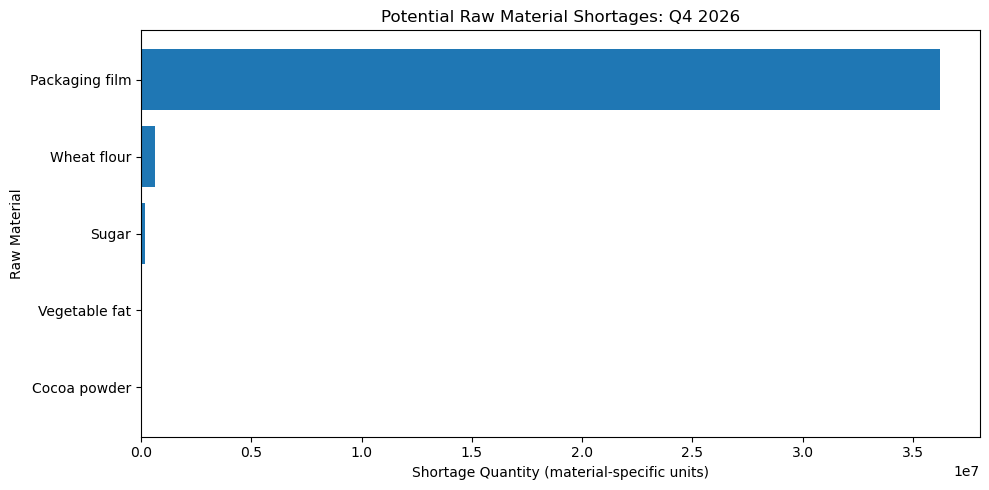

In [30]:
#Visualizing material shortages
plt.figure(figsize=(10, 5))

plt.barh(
    df_stockouts["material"],
    df_stockouts["shortage_qty"]
)

plt.title("Potential Raw Material Shortages: Q4 2026")
plt.xlabel("Shortage Quantity (material-specific units)")
plt.ylabel("Raw Material")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [44]:
#Saving the MRP results
df_mrp.to_csv(
    OUTPUT_DIR / "q4_mrp_results.csv",
    index=False
)

print("MRP results saved successfully.")

MRP results saved successfully.


In [ ]:
#Module 3: Production Optimization Using PuLP

In [31]:
# Defining daily production scenario

daily_demand = {
    "Yale Cabin 25g": 180_000,
    "Yale Glucose 35g": 150_000,
    "Yale Speedy Chocolate 40g": 120_000,
    "Sumal Shortcake": 100_000
}

print("Total daily demand:")
print(f"{sum(daily_demand.values()):,} packs")



Total daily demand:
550,000 packs


In [50]:
# Defining production lines and production rates

production_rates = {
    ("Line A", "Yale Cabin 25g"): 10_000,
    ("Line A", "Yale Glucose 35g"): 8_000,
    ("Line A", "Sumal Shortcake"): 7_000,

    ("Line B", "Yale Cabin 25g"): 9_000,
    ("Line B", "Yale Speedy Chocolate 40g"): 6_000,
    ("Line B", "Sumal Shortcake"): 8_000
}

print("Available line and product combinations:")

for (line, sku), rate in production_rates.items():
    print(f"{line} | {sku} | {rate:,} packs/hour")


Available line and product combinations:
Line A | Yale Cabin 25g | 10,000 packs/hour
Line A | Yale Glucose 35g | 8,000 packs/hour
Line A | Sumal Shortcake | 7,000 packs/hour
Line B | Yale Cabin 25g | 9,000 packs/hour
Line B | Yale Speedy Chocolate 40g | 6,000 packs/hour
Line B | Sumal Shortcake | 8,000 packs/hour


In [33]:
#Creating optimization model

model = pulp.LpProblem(
    "Sumal_Q4_Production_Planning",
    pulp.LpMaximize
)

print("Optimization model created.")

Optimization model created.
